# Análisis exploratorio y auditoría de las hojas de vida

En este capítulo auditamos el corpus de Jarvis antes de modelar: 2484 hojas de vida en inglés, cada una con su texto plano, su versión HTML y una de 24 categorías profesionales. Como el contexto es la selección de personal, la auditoría incluye información personal, atributos protegidos y atajos que un clasificador podría aprender en lugar de la tarea. El notebook lee `results/eda/nlp/`, que genera `python scripts/eda.py nlp`. Las estadísticas de vocabulario, n-gramas y *log-odds* se calculan solo con el conjunto de entrenamiento.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display

from project.book_utils import CAT, MUTED, need, style

style()
pd.set_option("display.precision", 3)
docs = need("eda/nlp/docs.pkl")
dup = need("eda/nlp/duplicates_split.pkl")
freq = need("eda/nlp/frequencies.pkl")

## Clases

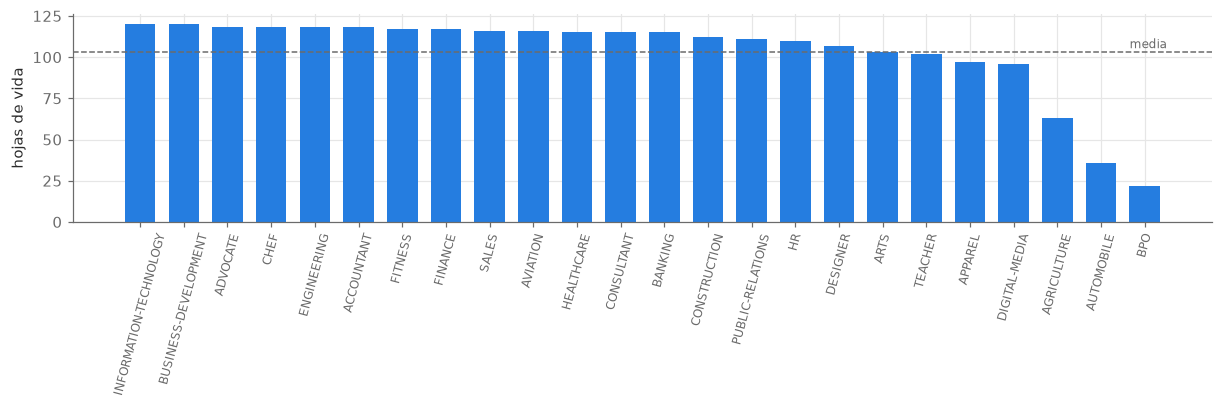

Clases: **24**. Mayor: INFORMATION-TECHNOLOGY (120); menor: BPO (22). Razón de desbalance: **5.45**. Entropía normalizada: **0.987**.

In [2]:
vc = docs.Category.value_counts()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(vc.index, vc.values, color=CAT[0], width=0.7)
ax.set_ylabel("hojas de vida"); ax.tick_params(axis="x", rotation=75, labelsize=8)
ax.axhline(vc.mean(), color=MUTED, lw=1, ls="--"); ax.text(len(vc) - 0.5, vc.mean() + 2, "media", ha="right", color=MUTED, fontsize=8)
plt.show()
display(Markdown(f"Clases: **{len(vc)}**. Mayor: {vc.index[0]} ({vc.iloc[0]}); menor: {vc.index[-1]} ({vc.iloc[-1]}). "
                 f"Razón de desbalance: **{vc.iloc[0] / vc.iloc[-1]:.2f}**. "
                 f"Entropía normalizada: **{stats.entropy(vc) / np.log(len(vc)):.3f}**."))

Veintiuna clases tienen entre 96 y 120 ejemplos; tres quedan por debajo: AGRICULTURE (63), AUTOMOBILE (36) y BPO (22). La razón de desbalance de 5.5 no es extrema, pero BPO tiene 3 ejemplos en validación y 3 en prueba, por lo que su F1 por clase tendrá un intervalo muy ancho. Elegimos F1 macro como métrica primaria para que esas clases pesen lo mismo que las grandes, y lo acompañamos de F1 ponderado y MCC.

## Longitud

Medimos la longitud en palabras (separación por espacios), en tokens del limpiador estándar y en *tokens* WordPiece del *tokenizer* real de DistilBERT.

,p50,p90,p95,p99
palabras,757.0,1179.0,1399.0,2053.0
tokens (limpieza estándar),762.0,1195.0,1405.0,2109.0
tokens WordPiece,975.0,1549.0,1821.0,2774.0


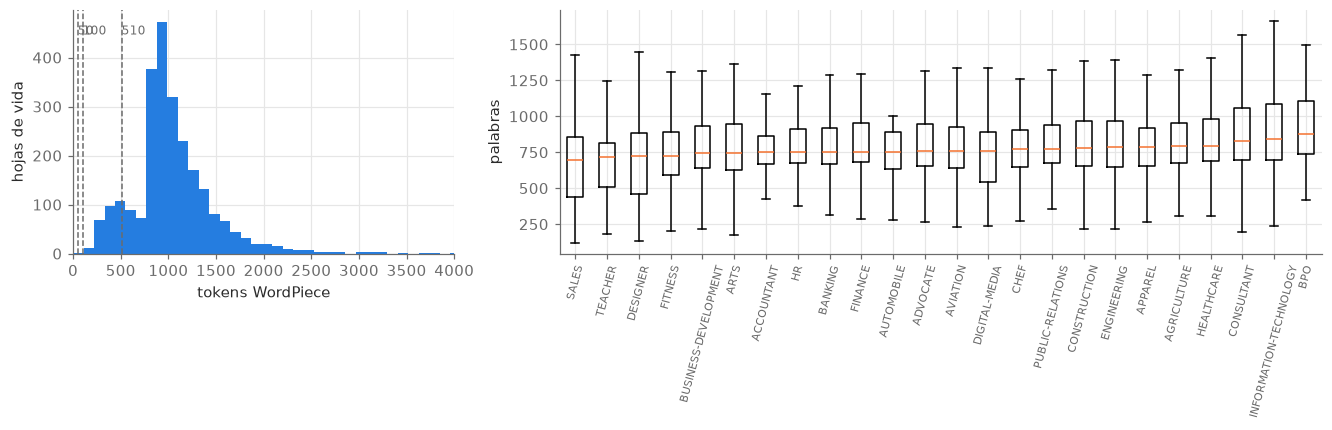

In [3]:
pcts = pd.DataFrame({c: np.percentile(docs[c], [50, 90, 95, 99]) for c in ["n_words", "n_tokens", "n_bert_tokens"]},
                    index=["p50", "p90", "p95", "p99"]).T
pcts.index = ["palabras", "tokens (limpieza estándar)", "tokens WordPiece"]
display(pcts.round(0))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 2]})
axes[0].hist(docs.n_bert_tokens, bins=60, color=CAT[0])
for v, lab in ((50, "50"), (100, "100"), (510, "510")):
    axes[0].axvline(v, color=MUTED, lw=1, ls="--"); axes[0].text(v, axes[0].get_ylim()[1] * 0.9, lab, color=MUTED, fontsize=8)
axes[0].set(xlabel="tokens WordPiece", ylabel="hojas de vida", xlim=(0, 4000))
order = docs.groupby("Category").n_words.median().sort_values().index
axes[1].boxplot([docs[docs.Category == c].n_words for c in order], showfliers=False)
axes[1].set_xticks(range(1, len(order) + 1), order, rotation=75, fontsize=7); axes[1].set_ylabel("palabras")
plt.show()

La mediana es de 757 palabras y 975 *tokens* WordPiece. Las secuencias de 50 y 100 tokens de la rejilla del enunciado cubren solo el 6.6 % y el 13 % de la mediana del documento limpio. El límite de 512 *tokens* de DistilBERT trunca casi todo el corpus. La tabla muestra la tasa de truncamiento por longitud y por clase.

In [4]:
trunc = pd.DataFrame({f"> {L}": [(docs.n_tokens > L).mean()] for L in (50, 100, 512)} |
                     {"> 510 WordPiece": [(docs.n_bert_tokens > 510).mean()]}, index=["global"])
display((trunc * 100).round(1).add_suffix(" (%)"))
by = docs.groupby("Category").apply(lambda d: (d.n_bert_tokens > 510).mean(), include_groups=False).sort_values()
display(Markdown(f"Truncamiento a 510 *tokens* WordPiece por clase: de **{by.min():.0%}** ({by.index[0]}) a **{by.max():.0%}** ({by.index[-1]})."))

,> 50 (%),> 100 (%),> 512 (%),> 510 WordPiece (%)
global,100.0,100.0,84.8,89.9


Truncamiento a 510 *tokens* WordPiece por clase: de **76%** (SALES) a **100%** (BPO).

Una hoja de vida empieza con el título del cargo y un resumen, y termina con la formación y las habilidades. Por eso truncamos con cabeza y cola: conservamos los primeros y los últimos tokens y descartamos el centro, que suele repetir la experiencia laboral. Con 512 tokens conservamos más de la mitad de una hoja de vida mediana. Mantuvimos 50 y 100 en la rejilla de la BiLSTM, como exige el enunciado, y añadimos 512 como desviación declarada.

## Frecuencias y n-gramas

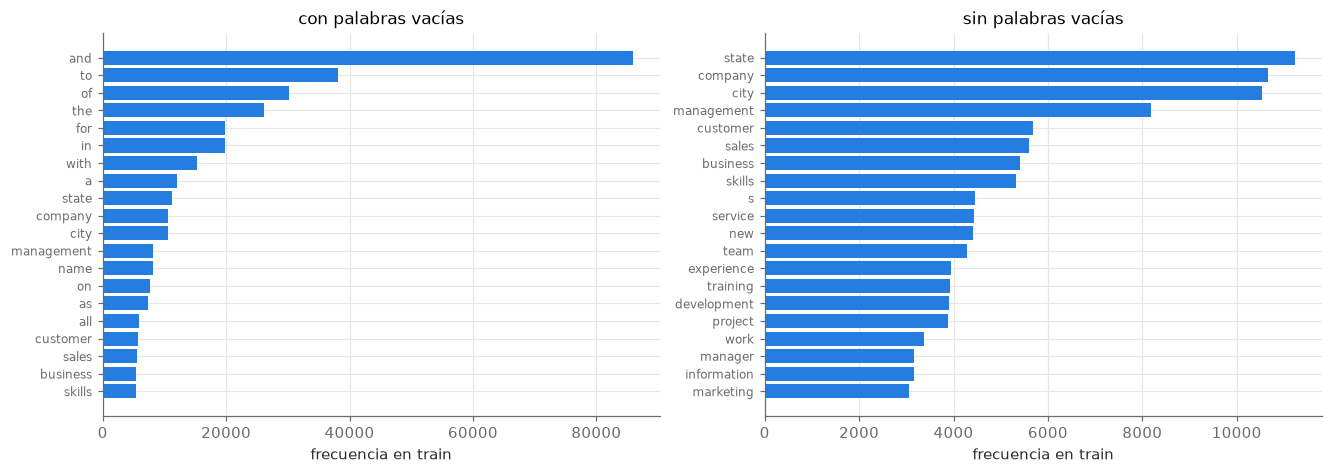

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, key, title in ((axes[0], "top_with_stop", "con palabras vacías"), (axes[1], "top_no_stop", "sin palabras vacías")):
    w, n = zip(*freq[key][:20])
    ax.barh(list(w)[::-1], list(n)[::-1], color=CAT[0]); ax.set_title(title); ax.set_xlabel("frecuencia en train")
    ax.tick_params(axis="y", labelsize=8)
plt.show()

Sin palabras vacías, las tres palabras más frecuentes son *state*, *company* y *city*. No son contenido: el corpus fue anonimizado con marcadores fijos («Company Name», «City», «State») en cada empleo. El bigrama más frecuente de casi todas las clases es *city state*. Para un modelo de bolsa de palabras son ruido; para un modelo secuencial consumen posiciones de la ventana. La tabla muestra los cinco bigramas más frecuentes de seis clases tras quitar esas plantillas.

In [6]:
TEMPL = {"city state", "company city", "company name", "state company", "name city", "current company", "university city", "college city"}
rows = {}
for c in ["ACCOUNTANT", "CHEF", "TEACHER", "AVIATION", "HR", "INFORMATION-TECHNOLOGY"]:
    rows[c] = [b for b, _ in freq["bigrams"][c] if b not in TEMPL][:5]
pd.DataFrame(rows).T.set_axis([f"#{i}" for i in range(1, 6)], axis=1)

,#1,#2,#3,#4,#5
ACCOUNTANT,general ledger,financial statements,accounts payable,accounts receivable,journal entries
CHEF,executive chef,customer service,food preparation,kitchen staff,sous chef
TEACHER,lesson plans,customer service,children s,high school,teacher company
AVIATION,customer service,high school,gpa 3,state usa,microsoft office
HR,human resources,employee relations,human resource,policies procedures,performance management
INFORMATION-TECHNOLOGY,information technology,project management,hardware software,information systems,help desk


Los bigramas restantes son vocabulario técnico de cada profesión (*general ledger*, *journal entries*). Los trigramas completos por clase están en `results/eda/nlp/frequencies.pkl`.

## Vocabulario: Zipf, Heaps y OOV

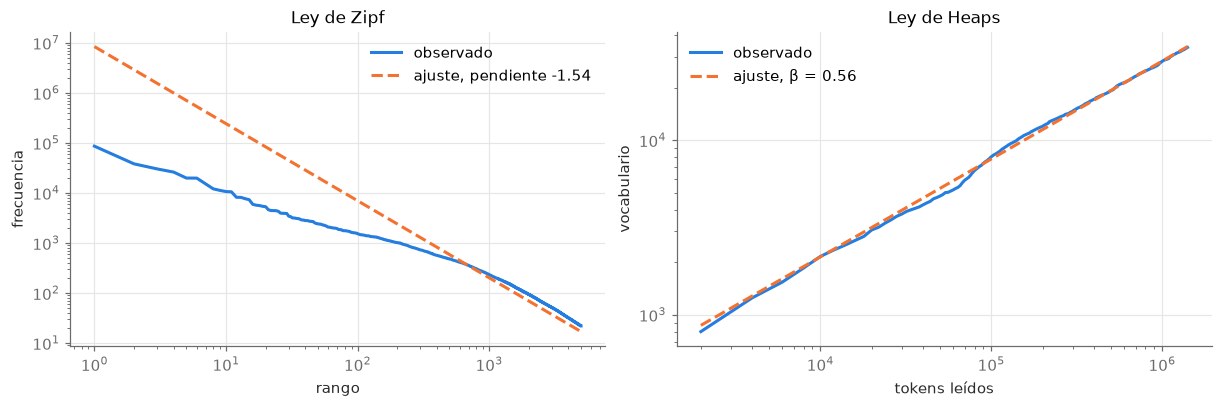

,OOV por token (%),OOV por tipo (%)
val,1.51,21.27
test,1.45,21.08


Vocabulario de entrenamiento: **34,059** tipos en **1,411,490** tokens.

In [7]:
fz = freq["zipf_freqs"]; r = np.arange(1, len(fz) + 1)
n_seen, v_seen = freq["heaps_curve"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].loglog(r, fz, color=CAT[0], label="observado")
axes[0].loglog(r, np.exp(freq["zipf_intercept"]) * r ** freq["zipf_slope"], color=CAT[1], ls="--", label=f"ajuste, pendiente {freq['zipf_slope']:.2f}")
axes[0].set(xlabel="rango", ylabel="frecuencia", title="Ley de Zipf"); axes[0].legend()
axes[1].loglog(n_seen, v_seen, color=CAT[0], label="observado")
axes[1].loglog(n_seen, np.exp(freq["heaps_logK"]) * np.asarray(n_seen) ** freq["heaps_beta"], color=CAT[1], ls="--", label=f"ajuste, β = {freq['heaps_beta']:.2f}")
axes[1].set(xlabel="tokens leídos", ylabel="vocabulario", title="Ley de Heaps"); axes[1].legend()
plt.show()
oov = pd.DataFrame(freq["oov"]).T.mul(100).round(2)
oov.columns = ["OOV por token (%)", "OOV por tipo (%)"]
display(oov)
display(Markdown(f"Vocabulario de entrenamiento: **{freq['vocab_train']:,}** tipos en **{freq['n_tokens_train']:,}** tokens."))

La pendiente de Zipf (−1.54) es más pronunciada que el −1 clásico: pocas palabras de plantilla concentran mucha masa. El exponente de Heaps (β = 0.56) indica que el vocabulario sigue creciendo con el corpus. Solo el 1.5 % de los tokens de validación y prueba no aparece en entrenamiento, pero el 21 % de los tipos sí es nuevo: la cola del vocabulario (nombres de software, certificaciones) es donde FastText, con sub-palabras, puede ganar frente a Word2Vec con `<UNK>`.

## Duplicados y casi duplicados

Buscamos duplicados exactos con un *hash* SHA-1 del texto normalizado y casi duplicados con MinHash/LSH sobre *shingles* de 5 palabras (Jaccard ≥ 0.8).

In [8]:
display(pd.DataFrame({"hojas de vida": [dup["n_raw"]], "duplicados exactos excluidos": [dup["exact_dups"]],
                      "grupos de casi duplicados": [dup["near_dup_groups"]], "documentos en esos grupos": [dup["near_dup_docs"]]}))
dup["class_split"]

,hojas de vida,duplicados exactos excluidos,grupos de casi duplicados,documentos en esos grupos
0,2484,2,5,10


split,excluded_duplicate,test,train,val
Category,,,,
ACCOUNTANT,0,17,83,18
ADVOCATE,0,18,82,18
AGRICULTURE,0,10,44,9
APPAREL,0,15,67,15
ARTS,0,16,71,16
AUTOMOBILE,0,6,25,5
AVIATION,1,18,81,17
BANKING,0,18,80,17
BPO,0,3,16,3


Eliminamos los 2 duplicados exactos antes de partir y asignamos cada grupo de casi duplicados a una sola partición. La tasa de duplicación es del 0.5 %. Si los hubiéramos dejado cruzar, a lo sumo 7 de 373 documentos de prueba (1.9 %) habrían tenido un gemelo en entrenamiento; con un clasificador que acierte esos casos con seguridad, la exactitud de prueba se inflaría como máximo en 1.9 puntos. La partición estratificada deja al menos 3 ejemplos de cada clase en prueba.

## Palabras discriminativas y atajos

Calculamos el *log-odds* con prior informativo de Dirichlet {cite:p}`monroe2008fightin` de cada clase frente al resto. Un *z*-score mayor que 1.96 equivale a un intervalo de confianza al 95 % que excluye la igualdad de uso.

In [9]:
lo = need("eda/nlp/log_odds.pkl")
pd.DataFrame({c: [f"{w} ({z:.0f})" for w, z in zip(d.word[:6], d.z[:6])] for c, d in lo.items()}).T.set_axis([f"#{i}" for i in range(1, 7)], axis=1)

,#1,#2,#3,#4,#5,#6
ACCOUNTANT,accounting (60),financial (43),accounts (40),accountant (39),tax (34),ledger (30)
ADVOCATE,advocate (26),patient (16),customer (16),care (14),patients (14),aix (13)
AGRICULTURE,agriculture (19),o (17),land (15),jamaica (11),agricultural (11),natural (11)
APPAREL,store (27),fashion (22),merchandising (21),apparel (17),product (17),merchandise (16)
ARTS,arts (37),students (28),school (25),art (22),student (21),teacher (21)
AUTOMOBILE,claims (24),tibco (14),liability (13),customer (12),automobile (12),police (11)
AVIATION,aircraft (32),aviation (31),flight (27),maintenance (21),navy (19),military (17)
BANKING,banking (37),loan (24),mortgage (21),financial (21),bank (21),branch (19)
BPO,workforce (13),bpo (12),process (11),cisco (11),india (11),client (10)
BUSINESS-DEVELOPMENT,sales (45),business (34),development (26),marketing (24),market (19),territory (17)


En 17 de 24 clases, la palabra más discriminativa es el nombre de la categoría o su raíz (*accounting*, *teacher*, *hr*, *finance*); en las otras siete, el nombre aparece entre las cinco primeras. Eso no es un error de etiquetado: el título del cargo es la primera línea de cada hoja de vida.

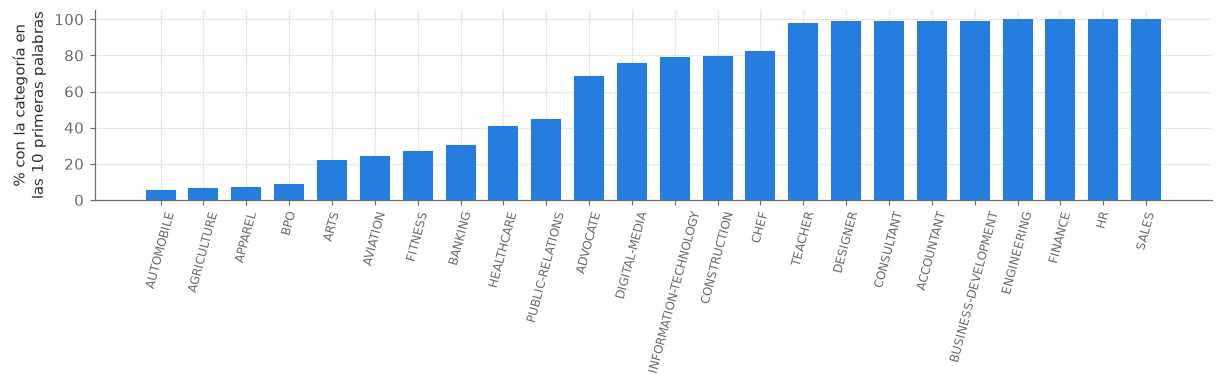

Hojas de vida cuya categoría aparece en las 10 primeras palabras: **67.8%**.

In [10]:
first = docs.groupby("Category").category_in_first10.mean().sort_values()
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(first.index, first.values * 100, color=CAT[0], width=0.7)
ax.set_ylabel("% con la categoría en\nlas 10 primeras palabras"); ax.tick_params(axis="x", rotation=75, labelsize=8)
plt.show()
display(Markdown(f"Hojas de vida cuya categoría aparece en las 10 primeras palabras: **{docs.category_in_first10.mean():.1%}**."))

En 9 clases, la categoría aparece en las primeras 10 palabras de más del 95 % de los documentos. Un clasificador puede alcanzar un F1 alto leyendo solo el título. Para la tarea de clasificar una hoja de vida por su contenido, ese título es un atajo legítimo pero frágil. Lo verificamos en el capítulo de robustez con dos ablaciones: quitar la primera línea y enmascarar las palabras de la categoría en todo el texto.

Otros atajos candidatos son la anonimización y la geografía. Los marcadores *city* y *state* aparecen en el 100 % de los documentos y no discriminan. En cambio, en el *log-odds* aparecen palabras geográficas o institucionales: *jamaica* e *iowa* en AGRICULTURE, *india* en BPO, *navy* y *army* en AVIATION. Son *proxies* de origen nacional y de servicio militar.

## Estructura temática

Ajustamos un LDA con 24 tópicos sobre conteos de entrenamiento y comparamos el tópico dominante de cada documento con su clase. Además proyectamos los vectores TF-IDF (SVD de 100 componentes) con UMAP.

Información mutua normalizada tópico–clase: **0.381**; índice de Rand ajustado: **0.195**.

,palabras
T0,"data, analysis, product, web, systems, technology"
T1,"children, child, activities, play, daily, beha..."
T2,"marketing, client, customers, clients, account..."
T3,"financial, accounting, accounts, finance, tax,..."
T4,"customers, store, cash, inventory, merchandise..."
T5,"design, interior, arts, designer, home, project"
T6,"care, health, medical, patient, patients, serv..."
T7,"data, testing, test, application, sql, database"
T8,"employee, hr, human, employees, resources, ben..."
T9,"reports, administrative, microsoft, data, assi..."


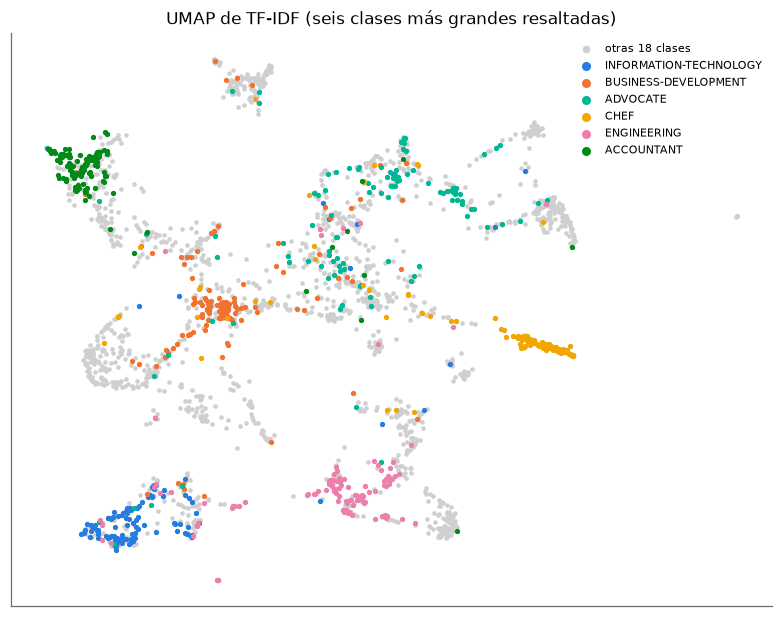

In [11]:
tp = need("eda/nlp/topics.pkl")
display(Markdown(f"Información mutua normalizada tópico–clase: **{tp['nmi']:.3f}**; índice de Rand ajustado: **{tp['ari']:.3f}**."))
display(pd.DataFrame({f"T{k}": ", ".join(v[:6]) for k, v in tp["top_words"].items()}, index=["palabras"]).T.head(24))
U = tp["umap"]; cats = tp["umap_cat"]
fig, ax = plt.subplots(figsize=(7, 5.5))
top6 = pd.Series(cats).value_counts().index[:6]
ax.scatter(U[:, 0], U[:, 1], s=4, color="#cfcfcf", label="otras 18 clases")
for i, c in enumerate(top6):
    m = cats == c
    ax.scatter(U[m, 0], U[m, 1], s=6, color=CAT[i], label=c)
ax.set(xticks=[], yticks=[], title="UMAP de TF-IDF (seis clases más grandes resaltadas)"); ax.legend(fontsize=7, markerscale=2)
plt.show()

La alineación tópico–clase es parcial (NMI 0.38). Los tópicos agrupan oficios afines (finanzas con contabilidad y banca; ventas con tiendas y vestuario) y dos tópicos reflejan artefactos de origen: fechas y números (T10) y plantillas administrativas (T9). Las clases con oficios afines son las candidatas a confusiones sistemáticas.

## Idioma, información personal y atributos protegidos

In [12]:
pii = pd.DataFrame({
    "correo electrónico": (docs.n_email > 0).mean(), "teléfono": (docs.n_phone > 0).mean(), "URL": (docs.n_url > 0).mean(),
    "año (1950–2029)": (docs.n_years > 0).mean(), "marcadores de anonimización (name/city/state)": (docs.n_namefield > 0).mean(),
    "mención de edad": docs.age_mention.mean(), "términos masculinos (he, his, mr…)": (docs.male_terms > 0).mean(),
    "términos femeninos (she, her, mrs…)": (docs.female_terms > 0).mean(),
}, index=["% de documentos"]).T.mul(100).round(1)
pii

,% de documentos
correo electrónico,0.8
teléfono,2.3
URL,3.9
año (1950–2029),99.7
marcadores de anonimización (name/city/state),100.0
mención de edad,1.1
"términos masculinos (he, his, mr…)",5.2
"términos femeninos (she, her, mrs…)",24.2


In [13]:
g = docs.assign(fem=docs.female_terms > 0, masc=docs.male_terms > 0).groupby("Category")[["fem", "masc"]].mean().mul(100).round(1)
g.columns = ["% con términos femeninos", "% con términos masculinos"]
g.sort_values("% con términos femeninos", ascending=False).head(8)

,% con términos femeninos,% con términos masculinos
Category,,
APPAREL,39.2,11.3
CONSULTANT,38.3,8.7
AUTOMOBILE,36.1,8.3
HR,33.6,1.8
PUBLIC-RELATIONS,30.6,4.5
INFORMATION-TECHNOLOGY,29.2,5.8
ACCOUNTANT,27.1,0.8
ENGINEERING,26.3,5.9


El corpus viene anonimizado: no hay nombres de personas, y los empleadores y ciudades están reemplazados por marcadores. Quedan, sin embargo, 20 documentos con correo electrónico, 57 con teléfono y 97 con URL. Las fechas aparecen en casi todos los documentos y permiten inferir la edad. Los términos de género aparecen en el 24 % (femeninos) y el 5 % (masculinos) de los documentos y no se reparten por igual entre clases. El análisis contrafactual de equidad del capítulo de robustez intercambia esos términos y mide el cambio en la predicción. Todos los textos están en inglés; un solo documento de entrenamiento (ID 12632728) tiene texto vacío y lo conservamos.

## Diversidad léxica y legibilidad

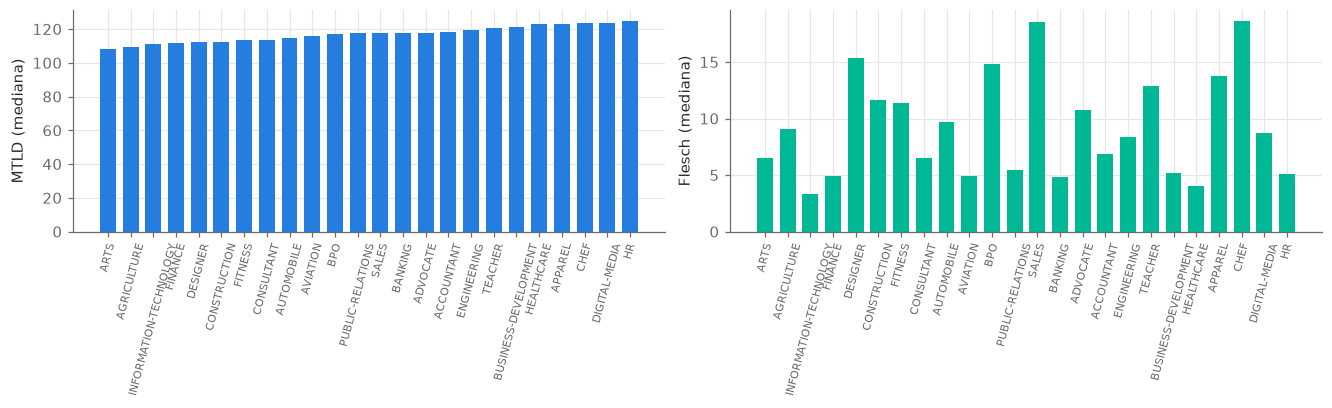

,H de Kruskal–Wallis,p,ε²
mtld,47.104,2.175e-03,0.010
flesch,190.129,2.870e-28,0.068
n_words,75.575,1.628e-07,0.021


In [14]:
lex = docs.groupby("Category")[["ttr", "mtld", "flesch"]].median().sort_values("mtld")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].bar(lex.index, lex.mtld, color=CAT[0], width=0.7); axes[0].set_ylabel("MTLD (mediana)")
axes[1].bar(lex.index, lex.flesch, color=CAT[2], width=0.7); axes[1].set_ylabel("Flesch (mediana)")
for ax in axes:
    ax.tick_params(axis="x", rotation=75, labelsize=7)
plt.show()
kw = {c: stats.kruskal(*[d[c].dropna() for _, d in docs.groupby("Category")]) for c in ["mtld", "flesch", "n_words"]}
pd.DataFrame({c: {"H de Kruskal–Wallis": r.statistic, "p": r.pvalue,
                  "ε²": (r.statistic - 24 + 1) / (len(docs) - 24)} for c, r in kw.items()}).T

La diversidad léxica (MTLD de 108 a 125) y la longitud varían poco entre clases: aunque las diferencias son significativas, el tamaño del efecto es pequeño (ε² = 0.01 y 0.02). La legibilidad (Flesch, ε² = 0.07) sí separa a CHEF y SALES (≈ 19) y a BPO, APPAREL, TEACHER y FITNESS (11 a 15) de las profesiones financieras (≈ 5). Son estilos de redacción asociados al oficio, no atajos externos a la tarea.

## Interpretación cuantitativa

- **Balance de clases.** La razón de desbalance es 5.5 (120 frente a 22), y tres clases tienen menos de 65 ejemplos. Por eso usamos F1 macro como métrica primaria, estratificamos la partición, damos pesos balanceados a los modelos lineales y reportamos F1 por clase con intervalos.
- **Longitud.** La mediana es de 757 palabras y 975 *tokens* WordPiece; el 90 % de los documentos supera 510 *tokens*. `sequence_length` de 50 y 100 cubre una fracción mínima del texto; 512 con cabeza y cola cubre más de la mitad de la mediana.
- **Ruido.** 0.5 % de duplicados (2 exactos y 5 pares casi idénticos), un documento vacío y marcadores de anonimización en el 100 % de los textos. La tasa de error de etiqueta se estima con *confident learning* en el capítulo de resultados, a partir de las probabilidades fuera de muestra de la validación cruzada.
- **Riesgos de atajo y su verificación.** (1) El título del cargo en la primera línea: ablación de la primera línea y enmascarado de la categoría. (2) *Proxies* geográficos y de servicio militar en el *log-odds*: enmascarado de topónimos. (3) Términos de género: prueba contrafactual con intercambio de pronombres y tratamientos.